# Assignment 2: unified semantic-segmentation training

This notebook starts from the **original local TrashCan-Material dataset** and uses one shared EDA, split, dataset, preprocessing, and training path for each A2 model. Select U-Net, SegFormer color-off, or SegFormer color-on below; every selection is an independent run using its own config and output directory. U-Net starts from scratch. SegFormer loads its pinned ADE20K initialization.

**No Google Drive mount or Drive access is used.** The notebook reuses the extracted dataset or local archive when available. If both are missing, it downloads the official archive into the repository's `data/TrashCan/` folder; the same flow works in local and Colab runtimes.

The current protocol is still draft. The development run is available for pipeline validation; the full main-run cell deliberately remains behind the repository's approval, pilot, and frozen-protocol gate. A small development run is not a benchmark result.

In [ ]:
from pathlib import Path

def find_repo(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'src' / 'dlbench' / 'a2').is_dir() and (candidate / 'configs' / 'a2' / 'unet.py').is_file():
            return candidate
    raise FileNotFoundError('Open this notebook from a Deep-Learning-Benchmark-Suite checkout or set REPO_ROOT manually.')

REPO_ROOT = find_repo(Path.cwd().resolve())
DATA_ROOT = REPO_ROOT / 'data' / 'TrashCan' / 'dataset' / 'material_version'
DATA_ARCHIVE = REPO_ROOT / 'data' / 'TrashCan' / 'dataset.zip'
EDA_RUNS_ROOT = REPO_ROOT / 'data' / 'TrashCan' / 'eda_runs'
RUNS_ROOT = REPO_ROOT / 'runs' / 'a2'

## 0. Prepare the original dataset

Existing extracted data and archives are reused. The official archive is downloaded only when both are missing; extraction runs only when the expected dataset folders are absent.


## 1. Locate the repository and original dataset

In [ ]:
import os
import json
import subprocess
import sys
import zipfile
from datetime import datetime, timezone
from uuid import uuid4

def find_repo(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'src' / 'dlbench' / 'a2').is_dir() and (candidate / 'configs' / 'a2' / 'unet.py').is_file():
            return candidate
    raise FileNotFoundError('Open this notebook from a Deep-Learning-Benchmark-Suite checkout or set REPO_ROOT manually.')


os.chdir(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT / 'src'))
print('Repository:', REPO_ROOT)
print('Local dataset root:', DATA_ROOT)
print('Local EDA runs:', EDA_RUNS_ROOT)
print('Local run output:', RUNS_ROOT)

Repository: D:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite
Local dataset root: D:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\data\TrashCan\dataset\material_version
Local EDA runs: D:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\data\TrashCan\eda_runs
Local run output: D:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\runs\a2


In [ ]:
required_files = (
    DATA_ROOT / 'instances_train_trashcan.json',
    DATA_ROOT / 'instances_val_trashcan.json',
    DATA_ROOT / 'train',
    DATA_ROOT / 'val',
)
dataset_ready = all(path.exists() for path in required_files)

if dataset_ready:
    print(f'Using existing extracted dataset: {DATA_ROOT}')
elif DATA_ARCHIVE.is_file():
    print(f'Using existing dataset archive: {DATA_ARCHIVE}')
else:
    print('Dataset and archive are missing; downloading the official dataset archive.')
    DATA_ARCHIVE.parent.mkdir(parents=True, exist_ok=True)
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', 'playwright', 'nest_asyncio'
    ])
    is_colab = bool(os.environ.get('COLAB_RELEASE_TAG')) or Path('/content').is_dir()
    if is_colab:
        subprocess.check_call([
            sys.executable, '-m', 'playwright', 'install-deps', 'chromium'
        ])
    subprocess.check_call([
        sys.executable, '-m', 'playwright', 'install', 'chromium'
    ])

    import asyncio
    import nest_asyncio
    from playwright.async_api import async_playwright

    nest_asyncio.apply()
    dataset_url = 'https://conservancy.umn.edu/bitstream/handle/11299/214865/dataset.zip'
    partial_archive = DATA_ARCHIVE.with_name(DATA_ARCHIVE.name + '.part')

    async def download_dataset_archive():
        async with async_playwright() as playwright:
            browser = await playwright.chromium.launch(headless=True)
            try:
                context = await browser.new_context(
                    user_agent=(
                        'Mozilla/5.0 (Windows NT 10.0; Win64; x64) '
                        'AppleWebKit/537.36 (KHTML, like Gecko) '
                        'Chrome/117.0.0.0 Safari/537.36'
                    )
                )
                page = await context.new_page()
                async with page.expect_download(timeout=300000) as download_event:
                    await page.goto(dataset_url)
                download = await download_event.value
                await download.save_as(str(partial_archive))
            finally:
                await browser.close()

    asyncio.run(download_dataset_archive())
    if not zipfile.is_zipfile(partial_archive):
        partial_archive.unlink(missing_ok=True)
        raise ValueError(f'Downloaded dataset is not a valid ZIP archive: {partial_archive}')
    partial_archive.replace(DATA_ARCHIVE)
    print(f'Dataset archive saved: {DATA_ARCHIVE} ({DATA_ARCHIVE.stat().st_size / (1024 * 1024):.1f} MiB)')

if not dataset_ready:
    if not DATA_ARCHIVE.is_file():
        raise FileNotFoundError(f'Dataset archive is missing: {DATA_ARCHIVE}')
    extraction_root = DATA_ROOT.parent.parent.resolve()
    extraction_root.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(DATA_ARCHIVE) as archive:
        for member in archive.infolist():
            destination = (extraction_root / member.filename).resolve()
            if not destination.is_relative_to(extraction_root):
                raise ValueError(f'Unsafe ZIP member path: {member.filename}')
        archive.extractall(extraction_root)

if not all(path.exists() for path in required_files):
    raise FileNotFoundError(
        f'Original dataset is incomplete under {DATA_ROOT}; expected annotation JSON files and train/val folders.'
    )
print(f'Original local dataset is ready: {DATA_ROOT}')

## 2. Check the Python environment

Install the project A2 extra in the selected environment before running if needed (`python -m pip install -e ".[a2]"`). Choose a compatible PyTorch/torchvision build for your hardware. The mask converter requires Pillow 12.3.0 to match the recorded target hashes.

In [24]:
import PIL
import torch

EXPECTED_PILLOW = '12.3.0'
if PIL.__version__ != EXPECTED_PILLOW:
    raise RuntimeError(f'Expected Pillow {EXPECTED_PILLOW} for the frozen rasterizer; found {PIL.__version__}.')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
WORKERS = 0
torch.set_num_threads(min(4, os.cpu_count() or 1))

def cli(*args):
    command = [sys.executable, '-m', 'dlbench.a2.cli', *map(str, args)]
    print('$', ' '.join(map(str, command)))
    subprocess.check_call(command, cwd=REPO_ROOT)

print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('Pillow:', PIL.__version__)
print('Device:', DEVICE)
if DEVICE == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

Python: 3.14.5
PyTorch: 2.14.0+cpu
Pillow: 12.3.0
Device: cpu


## 3. Run a fresh EDA locally and generate the new manifest

This step always runs EDA on the local original dataset in this notebook session; it never loads a pre-supplied EDA archive or reuses an earlier output folder. A unique output folder is created for this run, including the generated report, statistics, figures, QA samples, and manifest. It does not move or duplicate images. Manifest paths retain each image's original `train/` or `val/` location.

In [25]:
run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ') + '_' + uuid4().hex[:8]
EDA_OUTPUT = EDA_RUNS_ROOT / f'eda_v1_{run_id}'
from dlbench.a2.eda import run as run_eda

# These values are returned by this fresh EDA execution, not loaded from a supplied archive.
eda_metadata, eda_summary, eda_manifest = run_eda(DATA_ROOT, EDA_OUTPUT, seed=36)
MANIFEST = EDA_OUTPUT / 'splits' / 'trashcan_material_seed36_v1.json'
if not MANIFEST.is_file():
    raise FileNotFoundError(f'EDA did not create {MANIFEST}')
from dlbench.a2.data import read_manifest
verified_manifest = read_manifest(MANIFEST)
if verified_manifest['content_sha256'] != eda_manifest['content_sha256']:
    raise ValueError('Generated manifest changed between EDA and training validation.')
print('Fresh EDA output:', EDA_OUTPUT)
print('Generated manifest:', MANIFEST)

Measured 1000/7212 images
Measured 2000/7212 images
Measured 3000/7212 images
Measured 4000/7212 images
Measured 5000/7212 images
Measured 6000/7212 images
Measured 7000/7212 images
Split search 8/24; feasible best=0.09356642879375146
Split search 16/24; feasible best=0.09356642879375146
Split search 24/24; feasible best=0.09356642879375146
{
  "verification": {
    "unique_images": 7212,
    "unique_videos": 312,
    "pairwise_video_overlap": 0,
    "all_classes_meet_video_minima": true,
    "manifest_content_sha256_verified": true
  },
  "split": {
    "train": {
      "images": 5057,
      "videos": 207,
      "annotations": 8563
    },
    "validation": {
      "images": 1077,
      "videos": 54,
      "annotations": 1956
    },
    "test": {
      "images": 1078,
      "videos": 51,
      "annotations": 1817
    }
  },
  "content_sha256": "87905f1a97dd2c04194e049ca61d1a7f3bbe2942e9fe17dc2d737c371cdce943"
}
Fresh EDA output: D:\Course Materials\261\261 - DL\Assignment\Deep-Learning

## 4. Review statistics and samples from this EDA run

Each review below is a separate cell. Statistics, figures, QA images, and downloads are read from the unique `EDA_OUTPUT` created in section 3. Rerun section 3 before reviewing a new dataset run.

In [26]:
from html import escape
from IPython.display import display, HTML, Markdown, Image as NotebookImage, FileLink

if any(name not in globals() for name in ('EDA_OUTPUT', 'EDA_RUNS_ROOT', 'MANIFEST', 'eda_metadata', 'eda_summary', 'eda_manifest')):
    raise RuntimeError('Run section 3 first to generate a fresh EDA run before reviewing results.')
EDA_OUTPUT = EDA_OUTPUT.resolve()
if not EDA_OUTPUT.is_relative_to(EDA_RUNS_ROOT.resolve()) or not EDA_OUTPUT.is_dir():
    raise FileNotFoundError(f'Fresh EDA output is missing or outside the EDA runs folder: {EDA_OUTPUT}')
MANIFEST = MANIFEST.resolve()
if not MANIFEST.is_relative_to(EDA_OUTPUT) or not MANIFEST.is_file():
    raise FileNotFoundError(f'Fresh EDA manifest is missing or outside its output folder: {MANIFEST}')

# Re-read generated artifacts to ensure every review cell is tied to this EDA run.
disk_metadata = json.loads((EDA_OUTPUT / 'metadata.json').read_text(encoding='utf-8'))
disk_manifest = json.loads(MANIFEST.read_text(encoding='utf-8'))
if disk_metadata != eda_metadata or disk_manifest['content_sha256'] != eda_manifest['content_sha256']:
    raise ValueError('EDA review artifacts do not match the fresh run from section 3.')
pooled = eda_metadata['pooled']


def show_table(title, columns, rows):
    header = ''.join(f'<th>{escape(str(column))}</th>' for column in columns)
    body = ''.join('<tr>' + ''.join(f'<td>{escape(str(value))}</td>' for value in row) + '</tr>' for row in rows)
    style = ('<style>.eda-table-wrap{max-height:520px;overflow:auto;border:1px solid var(--vscode-panel-border,var(--jp-border-color2,#888));border-radius:8px}'
             '.eda-table{border-collapse:separate;border-spacing:0;width:100%;font:13px/1.45 var(--vscode-font-family,var(--jp-ui-font-family, sans-serif));color:var(--vscode-editor-foreground,var(--jp-ui-font-color1,#222));background:var(--vscode-editor-background,var(--jp-layout-color1,#fff))}'
             '.eda-table th,.eda-table td{padding:8px 12px;border-bottom:1px solid var(--vscode-panel-border,var(--jp-border-color2,#ddd));text-align:left;vertical-align:top}'
             '.eda-table th{position:sticky;top:0;background:var(--vscode-sideBar-background,var(--jp-layout-color2,#f3f5f7));font-weight:600;color:var(--vscode-editor-foreground,var(--jp-ui-font-color1,#222));z-index:1}'
             '.eda-table tbody tr:nth-child(even){background:color-mix(in srgb,var(--vscode-list-hoverBackground,var(--jp-layout-color2,#888)) 28%,var(--vscode-editor-background,var(--jp-layout-color1,#fff)))}'
             '.eda-table tbody tr:hover{background:var(--vscode-list-hoverBackground,var(--jp-layout-color2,#eee))}'
             '.eda-table tbody tr:last-child td{border-bottom:0}</style>')
    display(HTML(f'{style}<h4 style="margin:0 0 8px">{escape(title)}</h4><div class="eda-table-wrap">'
                 f'<table class="eda-table"><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table></div>'))

### Source dataset totals

Compare the original train/validation partitions with the pooled source data used to create the new split.

In [27]:
source_rows = [
    (name, f"{values['images']:,}", f"{values['videos']:,}", f"{values['annotations']:,}",
     f"{values['foreground_supervised_percent']:.2f}%", f"{values['ignore_percent']:.2f}%")
    for name, values in eda_metadata['source_partitions'].items()
]
source_rows.append((
    'Pooled', f"{pooled['images']:,}", f"{pooled['videos']:,}", f"{pooled['annotations']:,}",
    f"{pooled['foreground_supervised_percent']:.2f}%", f"{pooled['ignore_percent']:.2f}%"
))
show_table('Source totals used by this EDA run',
           ['Source', 'Images', 'Videos', 'Annotations', 'Supervised foreground (%)', 'Ignored (%)'],
           source_rows)

Source,Images,Videos,Annotations,Supervised foreground (%),Ignored (%)
train,"6,008",306,"9,741",10.60%,0.04%
val,"1,204",133,"2,595",10.68%,0.06%
Pooled,"7,212",312,"12,336",10.61%,0.04%


### New split totals

Review image, video, and annotation counts for the generated train, validation, and test splits.

In [28]:
split_rows = [
    (name.title(), f"{values['images']:,}", f"{values['images'] / pooled['images']:.1%}",
     f"{values['videos']:,}", f"{values['annotations']:,}")
    for name, values in eda_summary.items()
]
show_table('New video-disjoint split totals',
           ['Split', 'Images', 'Image share', 'Videos', 'Annotations'], split_rows)

Split,Images,Image share,Videos,Annotations
Train,"5,057",70.1%,207,"8,563"
Validation,"1,077",14.9%,54,"1,956"
Test,"1,078",14.9%,51,"1,817"


### Pixel accounting by split

Check how each split's native-resolution pixels are divided among foreground, background, ignored regions, and cross-class overlaps.

In [29]:
image_statistics = json.loads((EDA_OUTPUT / 'image_statistics.json').read_text(encoding='utf-8'))
conflicts_by_split = {
    split_name: sum(row['conflict_pixels'] for row in image_statistics if row['split'] == split_name)
    for split_name in eda_summary
}
pixel_rows = [
    (name.title(), f"{values['total_pixels']:,}", f"{values['foreground_union_pixels']:,}",
     f"{values['foreground_supervised_pixels']:,}", f"{values['background_pixels']:,}",
     f"{values['ignore_pixels']:,}", f"{conflicts_by_split[name]:,}")
    for name, values in eda_summary.items()
]
show_table('Native-resolution pixel accounting by new split',
           ['Split', 'Total pixels', 'Foreground union', 'Supervised foreground',
            'Background', 'Ignored', 'Cross-class conflicts'], pixel_rows)

Split,Total pixels,Foreground union,Supervised foreground,Background,Ignored,Cross-class conflicts
Train,"755,568,000","82,095,212","81,814,580","673,472,788","280,632","280,632"
Validation,"155,476,800","16,580,249","16,463,055","138,896,551","117,194","117,194"
Test,"163,814,400","15,848,604","15,809,586","147,965,796","39,018","39,018"


### Foreground label statistics: train

Compare object counts, annotated images, video coverage, and supervised pixel share for each foreground class in the training split.

In [30]:
split_name = 'train'
class_rows = [
    (f"{values['category_id']:02d} | {class_name}", f"{values['annotations']:,}",
     f"{values['annotated_images']:,}", f"{values['videos']:,}",
     f"{values['pixels']:,}", f"{values['percent_of_all_pixels']:.3f}%")
    for class_name, values in eda_summary[split_name]['classes'].items()
]
show_table('Foreground labels | train',
           ['Label', 'Objects', 'Annotated images', 'Videos', 'Supervised pixels', 'Share of split pixels'],
           class_rows)

Label,Objects,Annotated images,Videos,Supervised pixels,Share of split pixels
01 | rov,"2,422","1,941",99,"39,554,115",5.235%
02 | plant,359,350,17,"2,363,431",0.313%
03 | animal_fish,550,459,33,"4,421,227",0.585%
04 | animal_starfish,199,92,9,"123,280",0.016%
05 | animal_shells,212,105,3,"103,703",0.014%
06 | animal_crab,142,125,9,"788,795",0.104%
07 | animal_eel,218,187,24,"255,181",0.034%
08 | animal_etc,162,153,12,"804,932",0.107%
09 | trash_etc,"1,418","1,202",107,"9,144,786",1.210%
10 | trash_fabric,214,189,14,"2,285,115",0.302%


### Foreground label statistics: validation

Review per-class representation and supervised pixel coverage in the validation split.

In [31]:
split_name = 'validation'
class_rows = [
    (f"{values['category_id']:02d} | {class_name}", f"{values['annotations']:,}",
     f"{values['annotated_images']:,}", f"{values['videos']:,}",
     f"{values['pixels']:,}", f"{values['percent_of_all_pixels']:.3f}%")
    for class_name, values in eda_summary[split_name]['classes'].items()
]
show_table('Foreground labels | validation',
           ['Label', 'Objects', 'Annotated images', 'Videos', 'Supervised pixels', 'Share of split pixels'],
           class_rows)

Label,Objects,Annotated images,Videos,Supervised pixels,Share of split pixels
01 | rov,445,375,22,"7,163,611",4.608%
02 | plant,82,69,10,"586,232",0.377%
03 | animal_fish,117,88,7,"1,444,284",0.929%
04 | animal_starfish,167,23,3,"36,913",0.024%
05 | animal_shells,30,27,2,"86,594",0.056%
06 | animal_crab,133,30,3,"198,727",0.128%
07 | animal_eel,41,37,6,"56,701",0.036%
08 | animal_etc,42,37,6,"78,979",0.051%
09 | trash_etc,260,253,23,"1,921,324",1.236%
10 | trash_fabric,55,43,4,"422,040",0.271%


### Foreground label statistics: test

Review per-class representation and supervised pixel coverage in the held-out test split.

In [32]:
split_name = 'test'
class_rows = [
    (f"{values['category_id']:02d} | {class_name}", f"{values['annotations']:,}",
     f"{values['annotated_images']:,}", f"{values['videos']:,}",
     f"{values['pixels']:,}", f"{values['percent_of_all_pixels']:.3f}%")
    for class_name, values in eda_summary[split_name]['classes'].items()
]
show_table('Foreground labels | test',
           ['Label', 'Objects', 'Annotated images', 'Videos', 'Supervised pixels', 'Share of split pixels'],
           class_rows)

Label,Objects,Annotated images,Videos,Supervised pixels,Share of split pixels
01 | rov,450,405,24,"6,736,002",4.112%
02 | plant,66,63,5,"660,750",0.403%
03 | animal_fish,97,97,5,"1,576,765",0.963%
04 | animal_starfish,32,19,3,"22,368",0.014%
05 | animal_shells,7,7,2,"5,938",0.004%
06 | animal_crab,34,31,3,"196,053",0.120%
07 | animal_eel,84,35,5,"76,403",0.047%
08 | animal_etc,31,31,7,"176,854",0.108%
09 | trash_etc,361,285,23,"1,601,068",0.977%
10 | trash_fabric,45,37,3,"352,025",0.215%


### Source image resolutions

See how many source images have each resolution in each original partition and in the pooled dataset.

In [33]:
resolution_rows = [
    (source_name, resolution, f'{count:,}')
    for source_name, values in [*eda_metadata['source_partitions'].items(), ('Pooled', pooled)]
    for resolution, count in sorted(values['resolution_counts'].items())
]
show_table('Source image resolutions', ['Source', 'Resolution', 'Images'], resolution_rows)

Source,Resolution,Images
train,480x270,"3,000"
train,480x360,"3,008"
val,480x270,967
val,480x360,237
Pooled,480x270,"3,967"
Pooled,480x360,"3,245"


### Verification and data provenance

Confirm the generated split checks and record the dataset, converter, runtime, and source annotation hashes.

In [34]:
eda_verification = json.loads((EDA_OUTPUT / 'verification.json').read_text(encoding='utf-8'))
provenance = {
    'dataset': eda_metadata['dataset'],
    'runtime': eda_metadata['runtime'],
    'rasterizer_version': eda_metadata['rasterizer_version'],
    'source_annotation_sha256': eda_metadata['source_annotation_sha256'],
}
display(Markdown('### Verification and provenance'))
display(HTML(f'<pre>{escape(json.dumps(eda_verification, indent=2))}</pre>'))
display(HTML(f'<pre>{escape(json.dumps(provenance, indent=2))}</pre>'))

### Verification and provenance

### EDA report

Read the narrative report produced by this EDA run.

In [35]:
report_path = EDA_OUTPUT / 'eda_report.md'
report_text = '\n'.join(
    line for line in report_path.read_text(encoding='utf-8').splitlines()
    if not line.startswith('![')
)
display(Markdown(report_text))

# TrashCan Material EDA and frozen video split

Measured on 5 October 2026 from the supplied archive. Counts of semantic pixels use the documented Pillow converter; polygon area metadata is not substituted for pixel counts.

## Dataset and labels

7,212 images, 12,336 object annotations, 16 foreground classes plus background, 312 filename video groups.

| ID | Class | Objects | Annotated images | Videos with supervised pixels | Supervised pixels |
|---|---|---:|---:|---:|---:|
| 1 | rov | 3317 | 2721 | 145 | 53453728 |
| 2 | plant | 507 | 482 | 32 | 3610413 |
| 3 | animal_fish | 764 | 644 | 45 | 7442276 |
| 4 | animal_starfish | 398 | 134 | 15 | 182561 |
| 5 | animal_shells | 249 | 139 | 7 | 196235 |
| 6 | animal_crab | 309 | 186 | 15 | 1183575 |
| 7 | animal_eel | 343 | 259 | 35 | 388285 |
| 8 | animal_etc | 235 | 221 | 25 | 1060765 |
| 9 | trash_etc | 2039 | 1740 | 153 | 12667178 |
| 10 | trash_fabric | 314 | 269 | 21 | 3059180 |
| 11 | trash_fishing_gear | 196 | 167 | 14 | 2007738 |
| 12 | trash_metal | 1126 | 1093 | 62 | 5502427 |
| 13 | trash_paper | 193 | 167 | 10 | 1259973 |
| 14 | trash_plastic | 1864 | 1753 | 97 | 17880093 |
| 15 | trash_rubber | 142 | 142 | 7 | 492758 |
| 16 | trash_wood | 340 | 324 | 20 | 3700036 |

## Semantic conversion policy

Converter `pillow_native_polygon_union_crossclass_ignore_v1`, Pillow 12.3.0. Object polygons are filled on the native image canvas; coverage outside the canvas is clipped. Same-class masks are unioned. Cross-class overlaps receive 255 and are excluded from loss/evaluation. Background is 0. Letterbox padding also receives 255.

## Original partitions and corrected pixel accounting

| Source | Images | Videos | Foreground union % | Supervised foreground % | Background % | Ignore % |
|---|---:|---:|---:|---:|---:|---:|
| train | 6008 | 306 | 10.6387 | 10.6016 | 89.3613 | 0.0371 |
| val | 1204 | 133 | 10.7428 | 10.6829 | 89.2572 | 0.0599 |

127 source video groups occur in both original train and validation. The original labels remain accessible in their original folders.

## New split

| Split | Images | Image share % | Videos | Annotations |
|---|---:|---:|---:|---:|
| train | 5057 | 70.12 | 207 | 8563 |
| validation | 1077 | 14.93 | 54 | 1956 |
| test | 1078 | 14.95 | 51 | 1817 |

Seed 36; each class has at least three train videos and two videos in each of validation and test. Candidate assignment uses metadata only, with 24 deterministic greedy/local-search restarts. Exact percentages may differ from 70/15/15 because videos are indivisible.

| Class | Train videos | Validation videos | Test videos |
|---|---:|---:|---:|
| rov | 99 | 22 | 24 |
| plant | 17 | 10 | 5 |
| animal_fish | 33 | 7 | 5 |
| animal_starfish | 9 | 3 | 3 |
| animal_shells | 3 | 2 | 2 |
| animal_crab | 9 | 3 | 3 |
| animal_eel | 24 | 6 | 5 |
| animal_etc | 12 | 6 | 7 |
| trash_etc | 107 | 23 | 23 |
| trash_fabric | 14 | 4 | 3 |
| trash_fishing_gear | 10 | 2 | 2 |
| trash_metal | 42 | 12 | 8 |
| trash_paper | 6 | 2 | 2 |
| trash_plastic | 61 | 16 | 20 |
| trash_rubber | 3 | 2 | 2 |
| trash_wood | 14 | 3 | 3 |



## QA from this execution







## Provenance

Working source: https://drive.google.com/drive/folders/1VwT0UyleGYyF9yrCtXaOwZpnp-ZRrfGD

See metadata.json for source hashes, runtime versions and mask-accounting checks. See splits/trashcan_material_seed36_v1.json for image paths, video assignments and canonical manifest digest.

### EDA figures

Inspect distribution and class-support plots generated for this run.

**material_distribution.png**

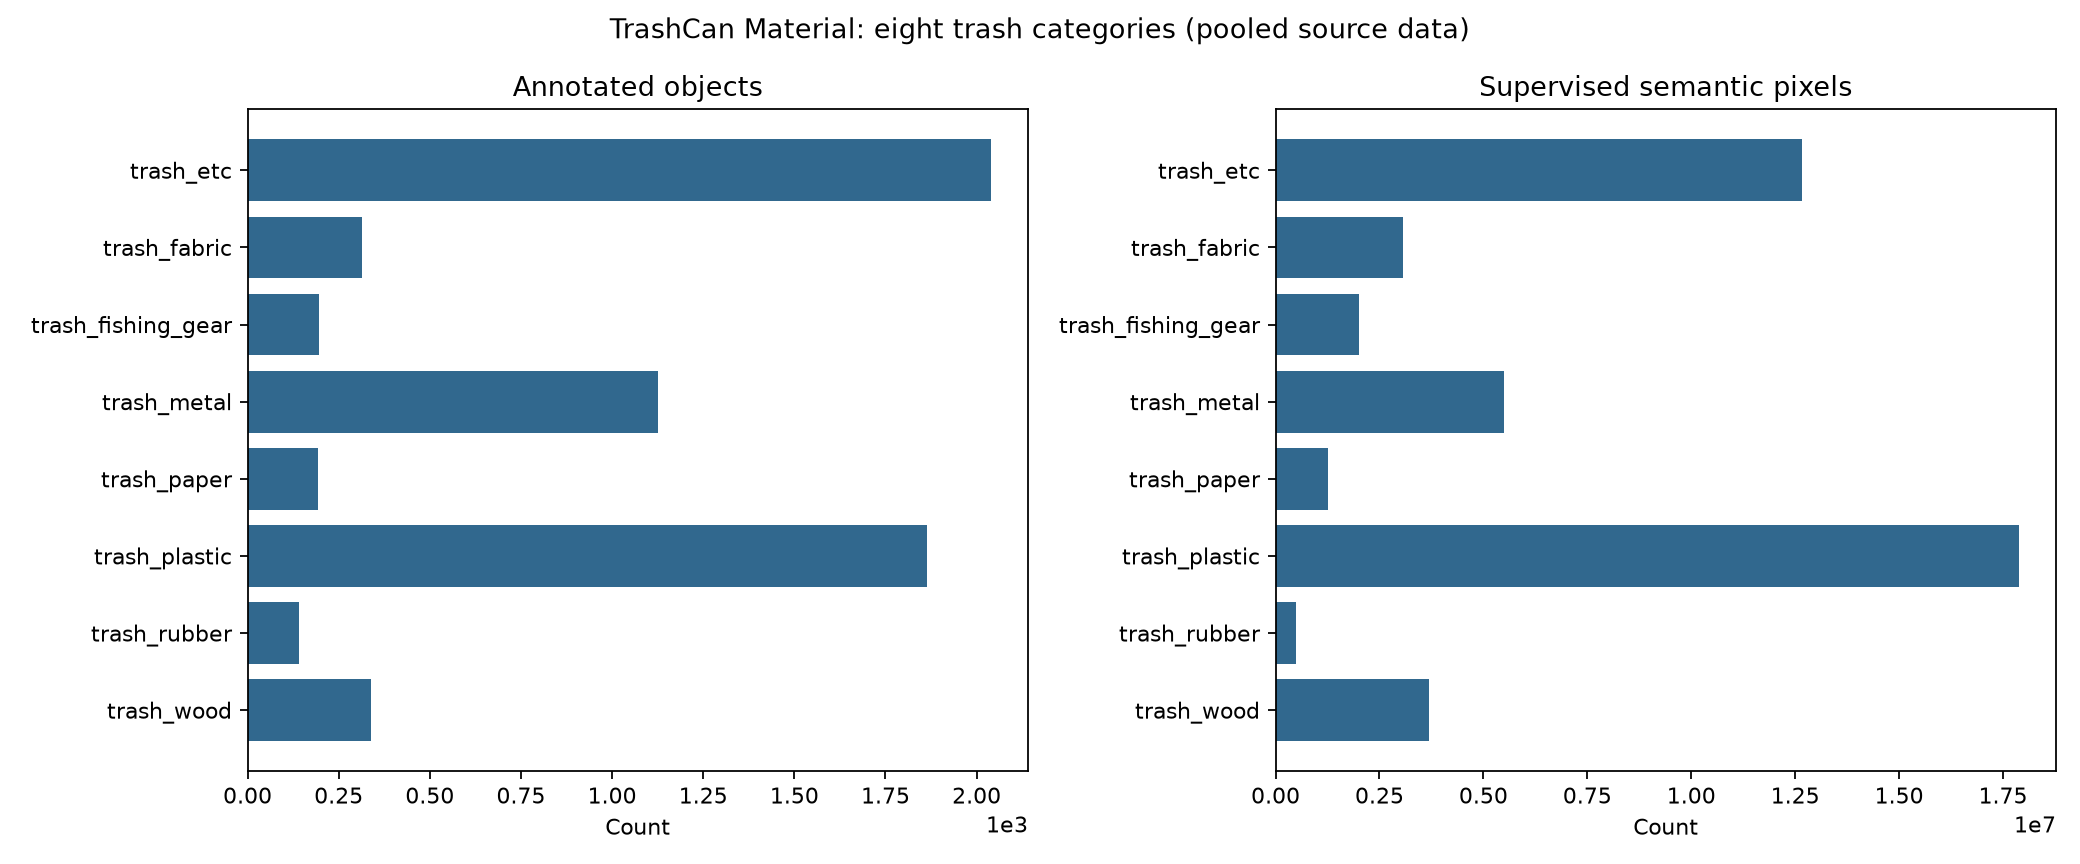

**split_class_video_support.png**

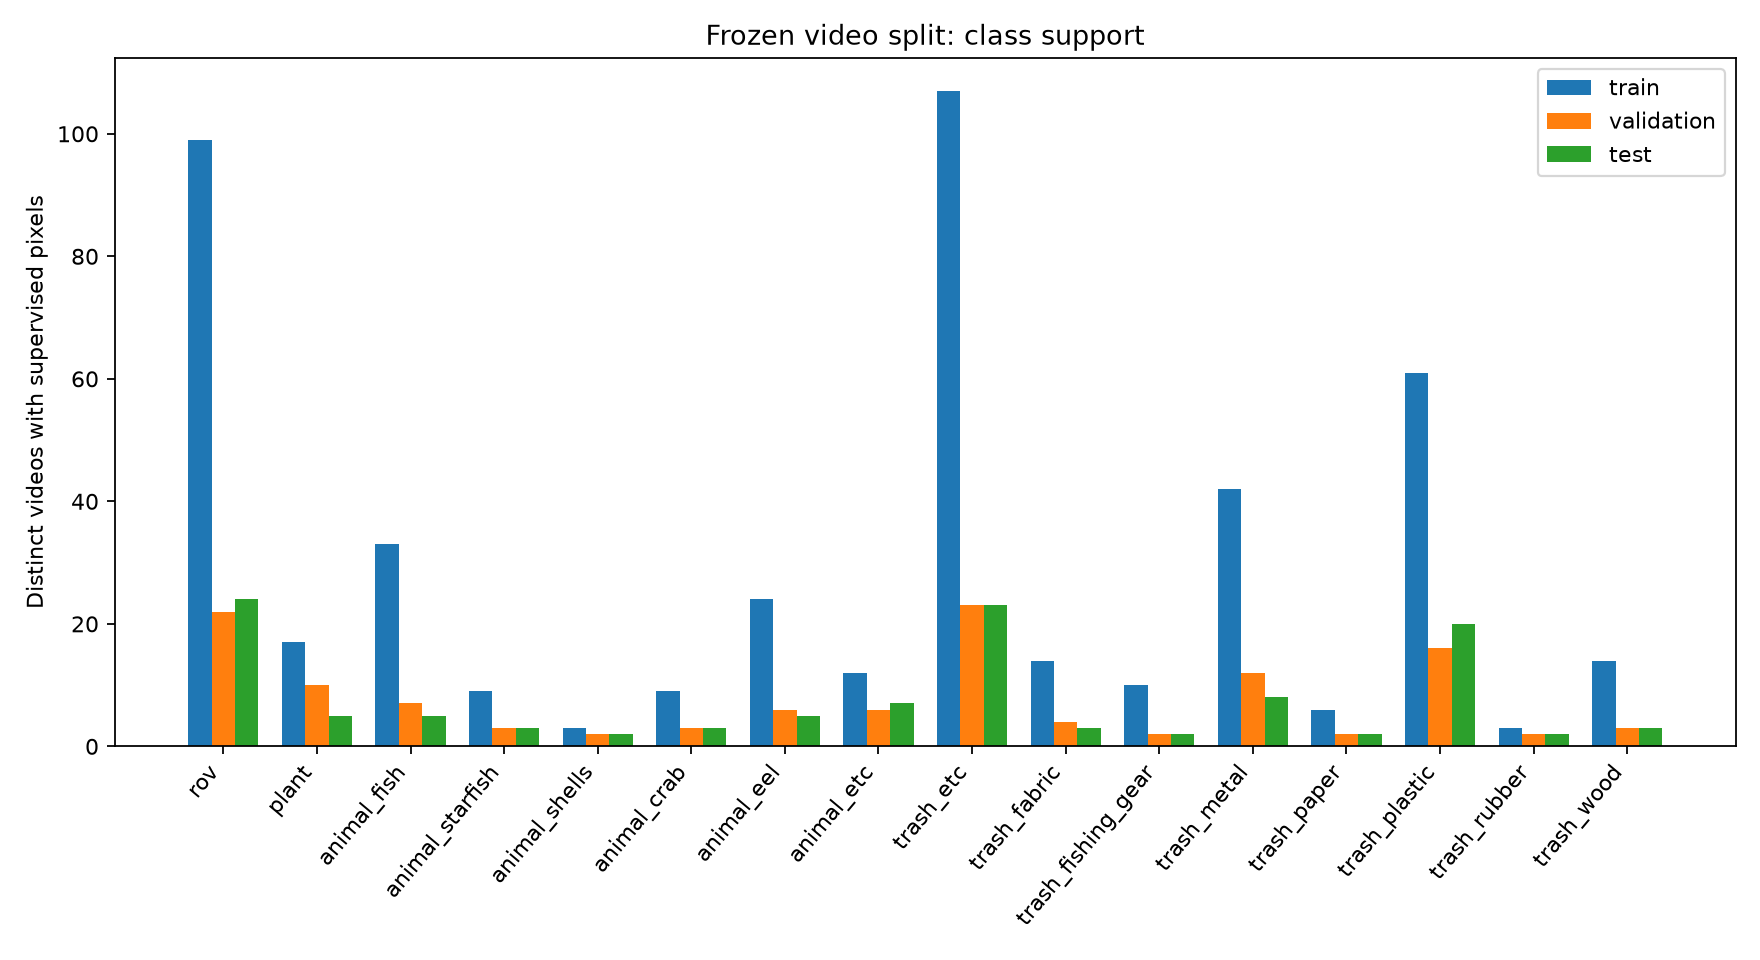

In [36]:
for figure_name in ('material_distribution.png', 'split_class_video_support.png'):
    figure_path = EDA_OUTPUT / 'figures' / figure_name
    if not figure_path.is_file():
        raise FileNotFoundError(f'Expected figure from the current EDA run: {figure_path}')
    display(Markdown(f'**{figure_name}**'))
    display(NotebookImage(filename=str(figure_path), width=850))

### QA image samples

Inspect RGB images and semantic overlays selected by the current EDA run.

### QA samples from the current EDA run

**train_vid_000109_frame0000036_semantic_qa.png**

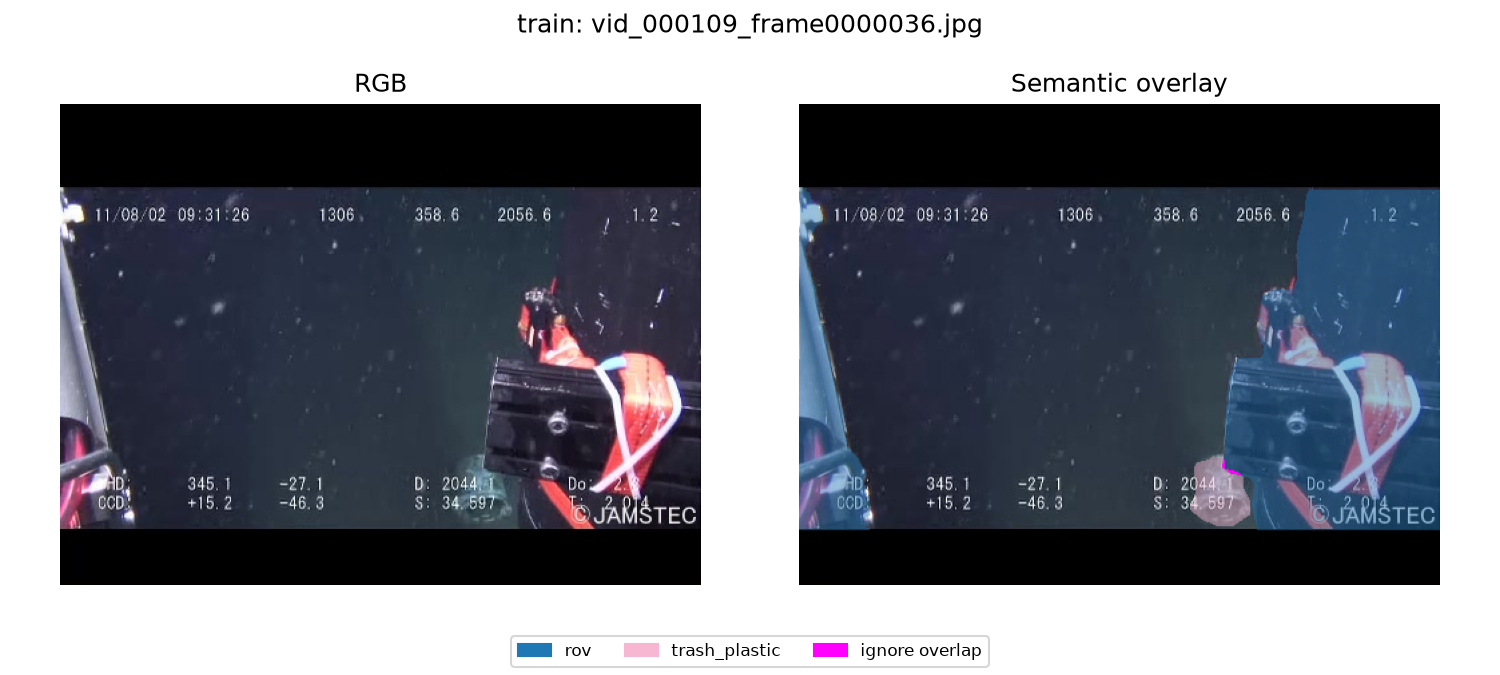

**train_vid_000021_frame0000016_semantic_qa.png**

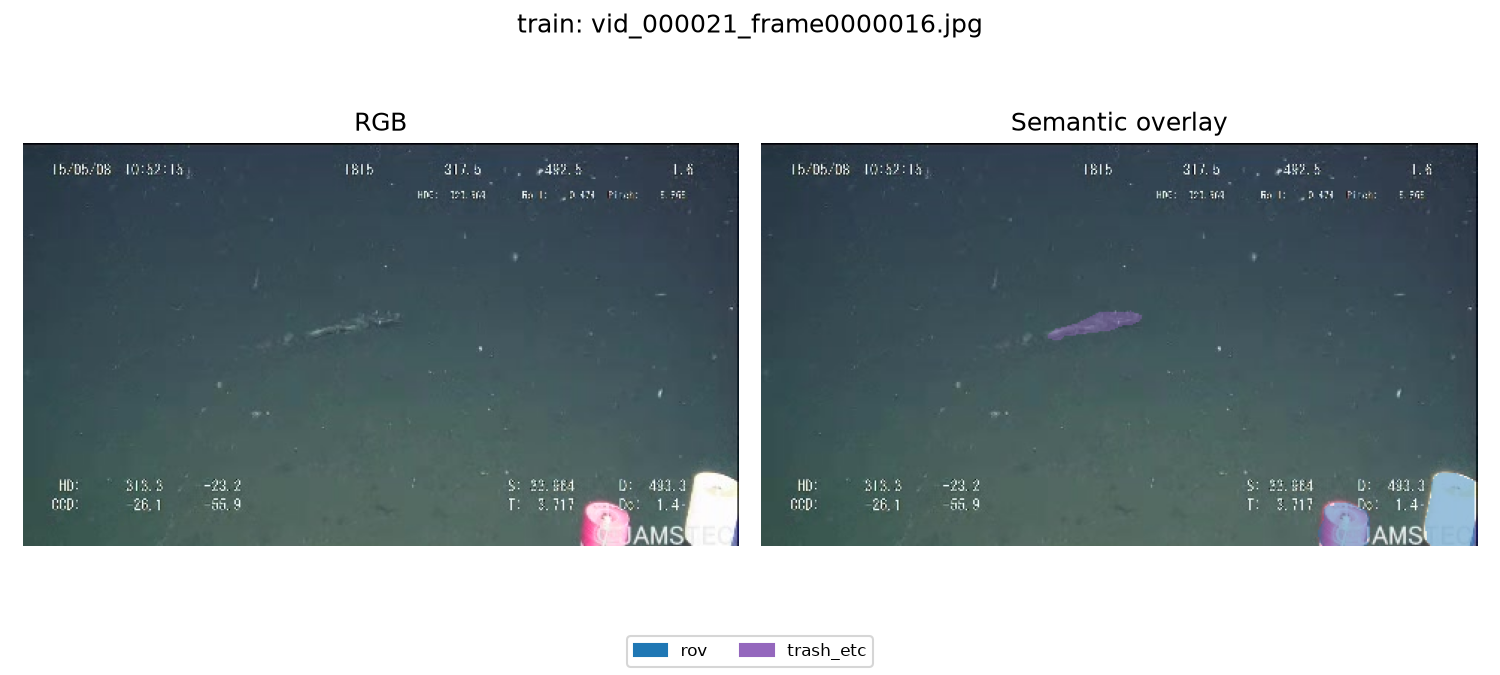

**validation_vid_000037_frame0000007_semantic_qa.png**

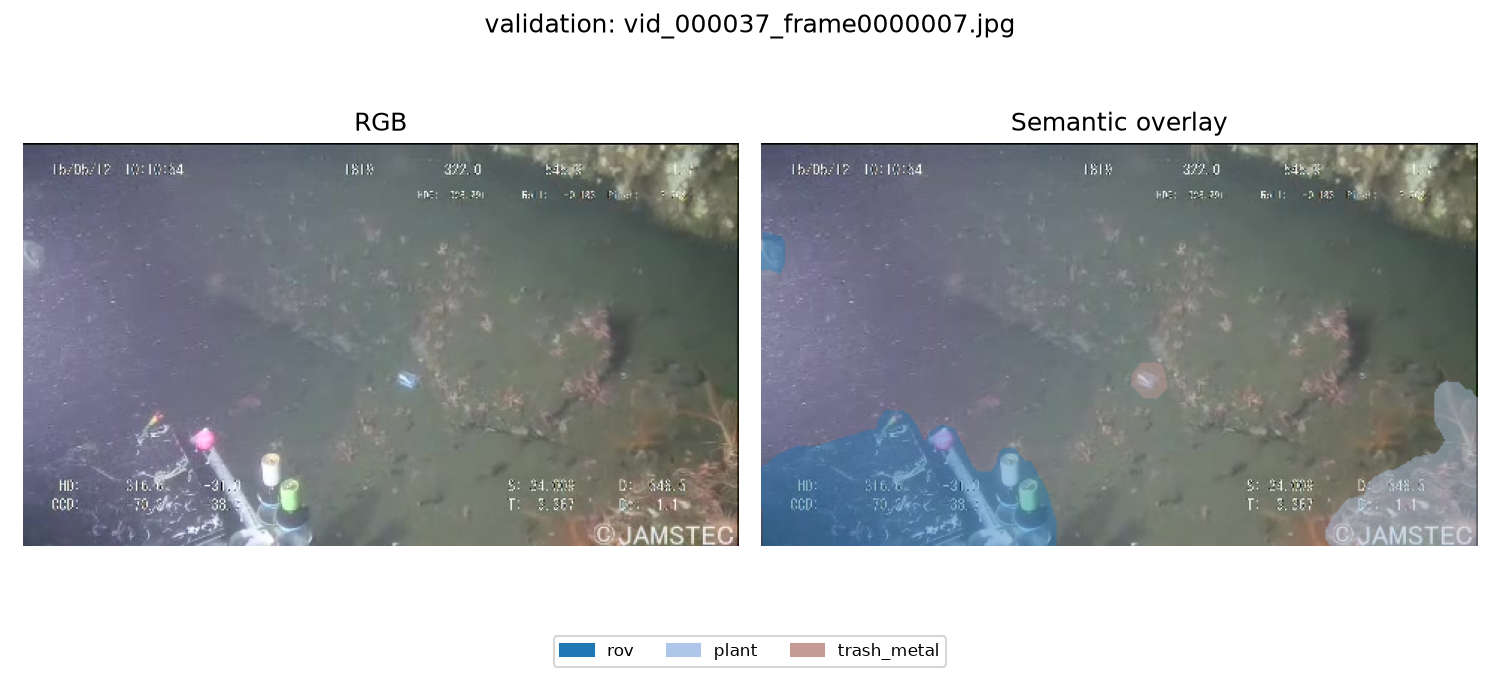

**validation_vid_000082_frame0000007_semantic_qa.png**

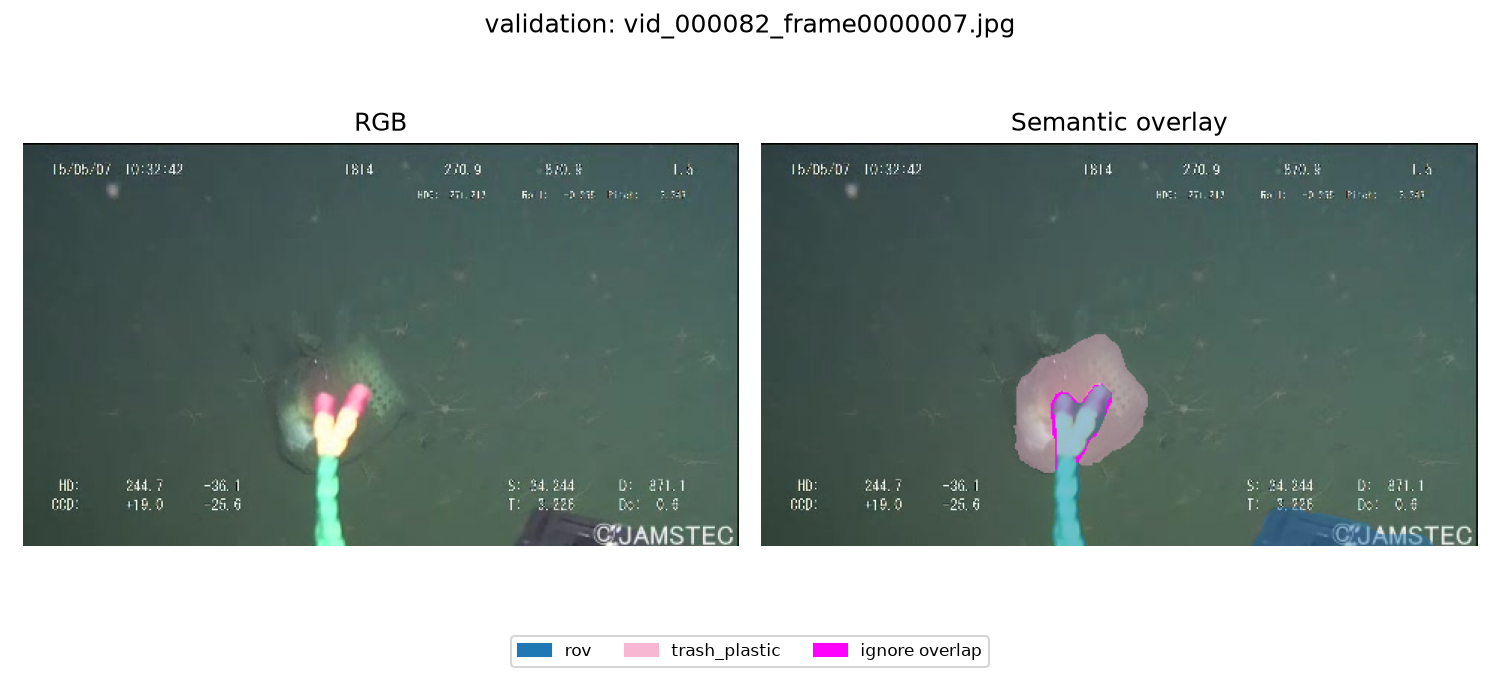

**test_vid_000091_frame0000011_semantic_qa.png**

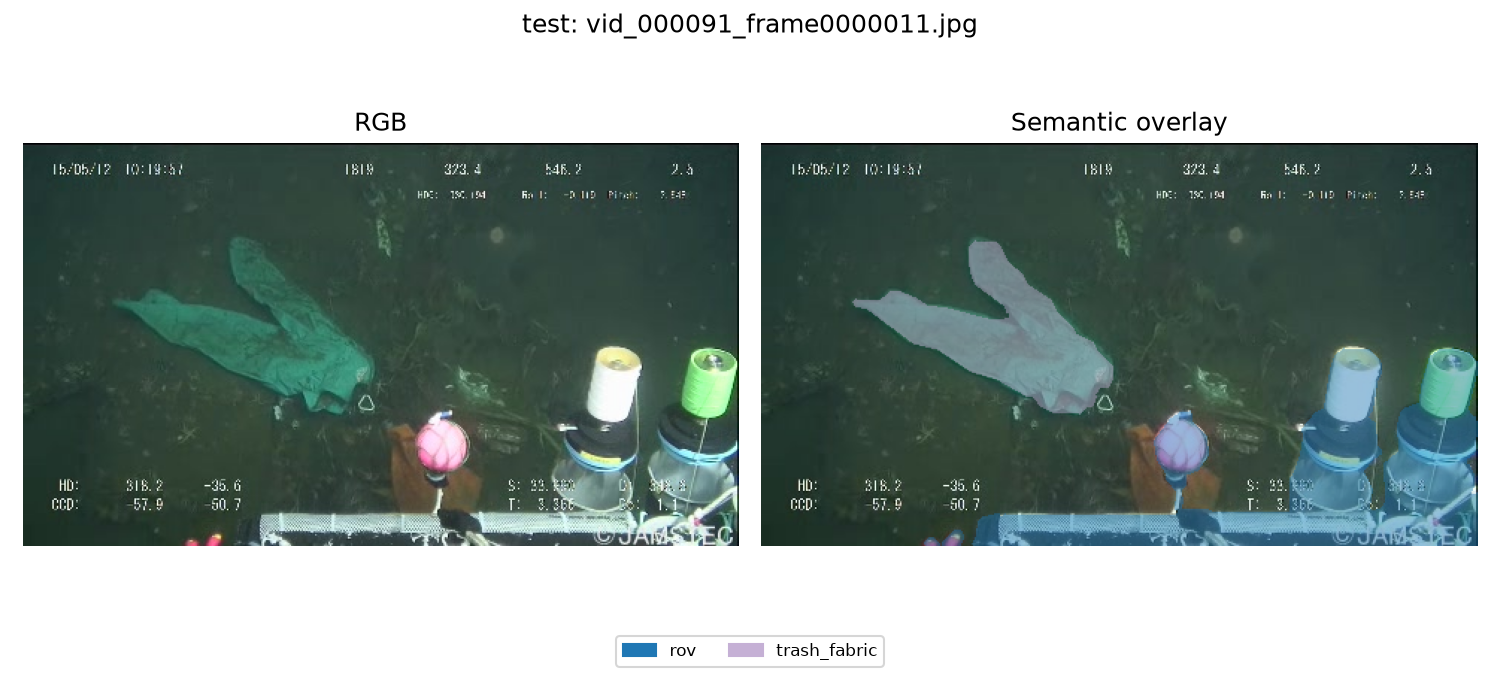

**test_vid_000085_frame0000042_semantic_qa.png**

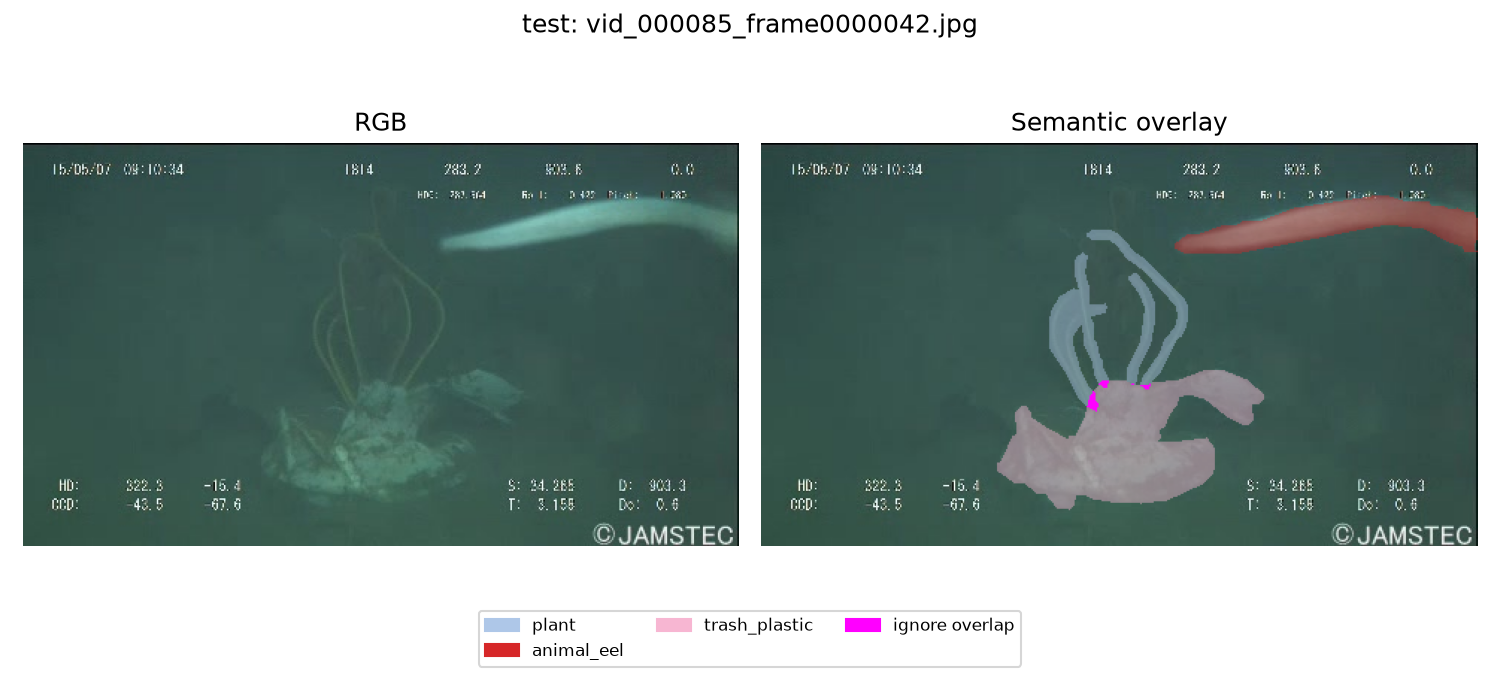

In [37]:
qa_files = json.loads((EDA_OUTPUT / 'qa_manifest.json').read_text(encoding='utf-8'))
display(Markdown('### QA samples from the current EDA run'))
for relative_path in qa_files:
    qa_path = (EDA_OUTPUT / relative_path).resolve()
    if not qa_path.is_relative_to(EDA_OUTPUT) or not qa_path.is_file():
        raise FileNotFoundError(f'QA sample listed by the current EDA run is missing: {qa_path}')
    display(Markdown(f'**{Path(relative_path).name}**'))
    display(NotebookImage(filename=str(qa_path), width=850))

### EDA output files

Open the detailed statistics, split manifest, summary, and verification files generated in this run.

In [38]:
display(Markdown('### Files generated by this EDA run'))
for artifact in ('image_statistics.json', 'split_manifest.csv', 'split_summary.json',
                 'metadata.json', 'verification.json'):
    artifact_path = EDA_OUTPUT / artifact
    if artifact_path.is_file():
        display(FileLink(str(artifact_path), result_html_prefix=f'{escape(artifact)}: '))

### Files generated by this EDA run

D:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\data\TrashCan\eda_runs\eda_v1_20261025T145203_214730Z_b1a80a22\image_statistics.json

D:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\data\TrashCan\eda_runs\eda_v1_20261025T145203_214730Z_b1a80a22\split_manifest.csv

D:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\data\TrashCan\eda_runs\eda_v1_20261025T145203_214730Z_b1a80a22\split_summary.json

D:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\data\TrashCan\eda_runs\eda_v1_20261025T145203_214730Z_b1a80a22\metadata.json

D:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\data\TrashCan\eda_runs\eda_v1_20261025T145203_214730Z_b1a80a22\verification.json

## 5. Select a model config and validate real data

`check-data` verifies annotation identity and membership against the manifest, then loads a small sample through the same dataset and mask conversion path used in training. This is a sample check, not a full image audit or model result.

In [39]:
# Choose exactly one independent experiment config: 'unet', 'segformer_off', or 'segformer_on'.
from dlbench.a2.config import load_config
MODEL_VARIANT = 'unet'
if MODEL_VARIANT not in {'unet', 'segformer_off', 'segformer_on'}:
    raise ValueError(f'Unsupported A2 model variant: {MODEL_VARIANT}')
CONFIG = REPO_ROOT / 'configs' / 'a2' / f'{MODEL_VARIANT}.py'
config = load_config(CONFIG)
RUN_LABEL = config['run']['name']
print('Selected model:', MODEL_VARIANT, '| run:', RUN_LABEL,
      '| initialization:', 'scratch' if MODEL_VARIANT == 'unet' else 'pinned ADE20K SegFormer-B0')
cli('validate-config', '--config', CONFIG)
for split in ('train', 'validation'):
    cli('check-data', '--config', CONFIG, '--data-root', DATA_ROOT,
        '--manifest', MANIFEST, '--split', split, '--limit', 4)

Selected model: unet | run: U | initialization: scratch
$ d:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\venv\Scripts\python.exe -m dlbench.a2.cli validate-config --config D:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\configs\a2\unet.py
$ d:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\venv\Scripts\python.exe -m dlbench.a2.cli check-data --config D:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\configs\a2\unet.py --data-root D:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\data\TrashCan\dataset\material_version --manifest D:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\data\TrashCan\eda_runs\eda_v1_20261025T145203_214730Z_b1a80a22\splits\trashcan_material_seed36_v1.json --split train --limit 4
$ d:\Course Materials\261\261 - DL\Assignment\Deep-Learning-Benchmark-Suite\venv\Scripts\python.exe -m dlbench.a2.cli check-data --config D:

## 6. Inspect a freshly preprocessed image and semantic target

This sample is loaded through the same `TrashCanDataset` preprocessing path used for training and the manifest generated in section 3. The gray `255` region is ignored by the loss and evaluation.


In [40]:
import matplotlib.pyplot as plt
import numpy as np
from dlbench.a2.config import load_config
from dlbench.a2.data import TrashCanDataset

validation_data = TrashCanDataset(DATA_ROOT, MANIFEST, 'validation', config['preprocessing'],
                                  seed=config['run']['seed'], color_jitter=config['run']['color_jitter'])
sample = validation_data[0]
image = sample['image'].permute(1, 2, 0).numpy()
image = np.clip(image * np.asarray(config['preprocessing']['std']) +
                np.asarray(config['preprocessing']['mean']), 0, 1)
mask = sample['mask'].numpy()
colors = plt.get_cmap('tab20')(np.minimum(mask, 16) / 19)[..., :3]
colors[mask == 255] = 0.5
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for axis, content, title in zip(axes, (image, colors, 0.6 * image + 0.4 * colors),
                                ('Image', 'Semantic target', 'Overlay')):
    axis.imshow(content)
    axis.set_title(title)
    axis.axis('off')
fig.suptitle(f"Image {sample['image_id']} / {sample['video_id']}")
plt.tight_layout()
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_37148\692405508.py:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 7. Choose the training mode for the selected model

The shared A2 trainer builds the selected architecture from its own config. U-Net uses fresh random initialization; SegFormer uses the pinned pretrained initialization and may need network access or a cached checkpoint. Training reads examples from the original local `train/` and `val/` folders according to the generated manifest. Each batch is converted on demand to 512×512 RGB images and integer semantic masks. Cross-entropy and foreground Dice ignore pixels labeled `255`; validation foreground mIoU selects the best checkpoint.

- **Development mode**: small subset and short run for pipeline/compute checks. Not a benchmark result.
- **Main mode**: full configured budget and split. It will only start once the A2 protocol is frozen and approval/pilot references are recorded. Do not bypass this gate.

In [41]:
RUN_DEVELOPMENT = False
RUN_MAIN = False
if RUN_DEVELOPMENT and RUN_MAIN:
    raise ValueError('Select only one training mode.')

DEVELOPMENT_LIMIT = 8
DEVELOPMENT_EPOCHS = 1
DEVELOPMENT_OUTPUT = RUNS_ROOT / f'{RUN_LABEL}-development-local'
MAIN_OUTPUT = RUNS_ROOT / f'{RUN_LABEL}-main-seed{config["run"]["seed"]}'

if RUN_DEVELOPMENT:
    if DEVELOPMENT_OUTPUT.exists():
        raise FileExistsError(f'Choose a new development output folder: {DEVELOPMENT_OUTPUT}')
    cli('train', '--config', CONFIG, '--data-root', DATA_ROOT, '--manifest', MANIFEST,
        '--output', DEVELOPMENT_OUTPUT, '--development', '--limit', DEVELOPMENT_LIMIT,
        '--epochs', DEVELOPMENT_EPOCHS, '--device', DEVICE, '--workers', WORKERS)
elif RUN_MAIN:
    if MAIN_OUTPUT.exists():
        raise FileExistsError(f'Choose a new main-run output folder: {MAIN_OUTPUT}')
    # The CLI validates approval, pilot evidence and frozen protocol before training.
    cli('train', '--config', CONFIG, '--data-root', DATA_ROOT, '--manifest', MANIFEST,
        '--output', MAIN_OUTPUT, '--device', DEVICE, '--workers', WORKERS)
else:
    print('Training is disabled. Set RUN_DEVELOPMENT=True for a small local check, or RUN_MAIN=True only after the main-run gate is cleared.')

Training is disabled. Set RUN_DEVELOPMENT=True for a small local check, or RUN_MAIN=True only after the main-run gate is cleared.


## 8. Inspect saved training history

The shared trainer writes `history.json`, `metrics.json`, metadata, source snapshots, and `best.pt`/`last.pt` in the selected local run directory. This cell plots the history if a run has completed.

In [42]:
from IPython.display import display, Markdown

if RUN_DEVELOPMENT:
    RESULT_DIR = DEVELOPMENT_OUTPUT
elif RUN_MAIN:
    RESULT_DIR = MAIN_OUTPUT
else:
    RESULT_DIR = None

if RESULT_DIR is not None and (RESULT_DIR / 'history.json').is_file():
    history = json.loads((RESULT_DIR / 'history.json').read_text(encoding='utf-8'))
    epochs = [row['epoch'] for row in history]
    train_loss = [row['train']['loss'] for row in history]
    val_loss = [row['validation']['loss'] for row in history]
    val_miou = [row['validation']['foreground_miou'] for row in history]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, train_loss, label='Train loss')
    axes[0].plot(epochs, val_loss, label='Validation loss')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()
    axes[1].plot(epochs, val_miou, marker='o', label='Validation foreground mIoU')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    display(Markdown(f"Run artifacts: `{RESULT_DIR}`"))
else:
    print('No training history found yet.')

No training history found yet.


## Interpretation and cautions

Only the training and validation partitions are used to fit/select the model. Keep the test split untouched until the protocol and model-selection choices are frozen. A development run or a successful notebook execution does not establish model quality. In Colab, local files are deleted when the runtime ends; copy needed artifacts out explicitly using your institution-approved method, without adding a Drive mount to this workflow.